# 10.1 — Who will be Most Improved in 2026-27? A preseason top 7

**Question.** Before a game has been played, who are our seven most likely Most Improved Player (MIP) winners for 2026-27? The top pick is our MIP prediction; the other six are the breakout candidates.

Notebook 10 named the winner *after* the season, from how much each player's numbers had changed. Here none of those changes exist yet. All we have is **last season** and **this preseason so far**.

**The problem with preseason.** Minutes are not real. Stars sit, deep-bench players get long runs, and a 6-minute player who gets 24 preseason minutes will not keep them. So:

**Decisions**
- **Performance is per 36 minutes, never totals.** Preseason form = his preseason rate (points, game score, shot volume per 36; true shooting) minus the same rate last season.
- **Small samples are shrunk.** Each preseason change is multiplied by *minutes ÷ (minutes + 150)*: 50 preseason minutes count for a quarter, 150 for half.
- **Centred within each preseason,** so the league-wide gap between preseason and regular-season basketball drops out.
- **Preseason minutes: option (b).** Increases count, decreases are ignored (a rested veteran's low minutes say nothing). Tested below, and kept only if it helps.
- **Baseline season** as in notebook 10: the most recent season with at least 33% of the games played.
- **Who is a candidate:** anyone with a baseline season and preseason minutes, except previous MIP winners and players who already averaged 22+ points last season (see 10.1B).
- **Model:** the same choice model as notebook 10 (one winner per season, chances add up to 100%), trained on the 14 preseasons from 2012-13 to 2025-26. Voting results are not used.

**Preseason is still being played.** Re-run this notebook (with `refresh_latest=True` in the first cell) once it ends.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.labels import MIP_WINNERS
from unicorn.mip import ChoiceModel
from unicorn.plotting import apply_style, BLUE, ORANGE, INK, INK2, MUTED, FIG_DIR, SURFACE
from unicorn.preseason import (load_preseason, preseason_frame, regular_rates, add_pool_flags, SHRINK_MINUTES,
                               LAST_SEASON_LEAN, PROFILE, MOMENTUM, PRE_FORM_LEAN, PRE_MINUTES, LEAN,
                               LAST_SEASON, PRE_FORM)
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
TARGET = "2026-27"
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
player_season = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)   # set refresh_latest=True to pull the newest preseason games

frame = add_pool_flags(preseason_frame(pre, regular, player_season), MIP_WINNERS)
now = pre[pre["season"] == TARGET]
print(f"preseason player-games: {len(pre):,} over {pre['season'].nunique()} preseasons")
print(f"{TARGET} preseason so far: {len(now):,} player-games, {now['game_id'].nunique()} games, through {now['game_date'].max():%d %b %Y}")
print(f"player-seasons with a baseline season and preseason minutes: {len(frame):,}; median preseason minutes {frame['pre_minutes'].median():.0f}")

preseason player-games: 32,926 over 15 preseasons
2026-27 preseason so far: 1,145 player-games, 39 games, through 12 Oct 2026
player-seasons with a baseline season and preseason minutes: 5,614; median preseason minutes 74


## 10.1A — How much of preseason carries into the season?

Before using preseason numbers, check what they have been worth in the past 14 seasons. Players with at least 60 preseason minutes who then played 20+ regular-season games.

In [2]:
actual = regular_rates(regular).rename(columns={"mpg": "mpg_act", "pts36": "pts36_act", "game_score36": "game_score36_act",
                                                "volume36": "volume36_act", "ts": "ts_act", "games": "games_act"})
D = frame[frame["season"] != TARGET].merge(actual[["player_id", "season_start", "games_act", "mpg_act", "pts36_act", "game_score36_act", "volume36_act", "ts_act"]],
                                           on=["player_id", "season_start"])
D = D[(D["pre_minutes"] >= 60) & (D["games_act"] >= 20)].copy()
D["mpg_change_act"] = D["mpg_act"] - D["mpg_last"]
bins = [-99, -10, -5, -2, 2, 5, 10, 99]
names = ["down 10+", "down 5 to 10", "down 2 to 5", "within 2", "up 2 to 5", "up 5 to 10", "up 10+"]
D["minutes_bin"] = pd.cut(D["pre_minutes_change_raw"], bins, labels=names)
minutes_table = D.groupby("minutes_bin", observed=True).agg(players=("player_id", "size"), preseason_change=("pre_minutes_change_raw", "mean"),
                                                             season_change=("mpg_change_act", "mean"))
minutes_table["share that carried over"] = minutes_table["season_change"] / minutes_table["preseason_change"]
minutes_table.loc["within 2", "share that carried over"] = np.nan
minutes_table.round(2)

,players,preseason_change,season_change,share that carried over
minutes_bin,,,,
down 10+,540,-12.32,-2.64,0.21
down 5 to 10,940,-7.48,-1.91,0.26
down 2 to 5,514,-3.46,-0.67,0.19
within 2,596,-0.03,0.70,NaN
up 2 to 5,314,3.40,2.52,0.74
up 5 to 10,300,7.18,4.29,0.60
up 10+,138,13.15,8.42,0.64


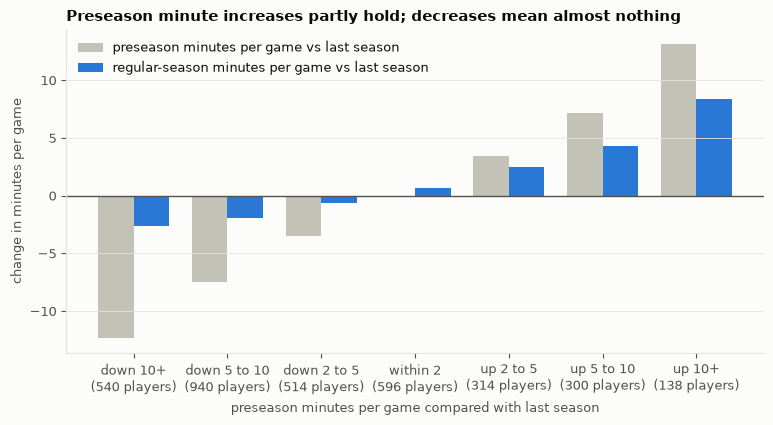

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(minutes_table)); w = 0.38
ax.bar(x - w / 2, minutes_table["preseason_change"], w, color=MUTED, label="preseason minutes per game vs last season")
ax.bar(x + w / 2, minutes_table["season_change"], w, color=BLUE, label="regular-season minutes per game vs last season")
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(x, [f"{n}\n({int(c):,} players)" for n, c in zip(minutes_table.index, minutes_table["players"])])
ax.set_xlabel("preseason minutes per game compared with last season"); ax.set_ylabel("change in minutes per game")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper left")
ax.set_title("Preseason minute increases partly hold; decreases mean almost nothing", loc="left")
fig.savefig(FIG_DIR / "10_1_preseason_minutes_carry_over.png", dpi=150, bbox_inches="tight")

In [4]:
bench = D[(D["mpg_last"] < 12) & (D["pre_mpg"] >= 20)]
print(f"bench players (< 12 min last season) given 20+ preseason minutes a game: {len(bench)}")
print(f"  last season {bench['mpg_last'].mean():.1f} → preseason {bench['pre_mpg'].mean():.1f} → regular season {bench['mpg_act'].mean():.1f} minutes per game; "
      f"{(bench['mpg_act'] >= 20).mean():.0%} kept 20+")

rows = []
for stat, label in [("volume36", "shot volume per 36"), ("pts36", "points per 36"), ("game_score36", "game score per 36"), ("ts", "true shooting %")]:
    pre_change = D[stat] - D[f"{stat}_last"]
    act_change = D[f"{stat}_act"] - D[f"{stat}_last"]
    ok = pre_change.notna() & act_change.notna()
    shrunk = pre_change * D["pre_reliability"]
    rows.append({"per-minute measure": label, "correlation: preseason change vs season change": np.corrcoef(pre_change[ok], act_change[ok])[0, 1],
                 "after shrinking by preseason minutes": np.corrcoef(shrunk[ok], act_change[ok])[0, 1],
                 "share of a preseason gain that shows up in the season": np.polyfit(pre_change[ok], act_change[ok], 1)[0]})
pd.DataFrame(rows).set_index("per-minute measure").round(2)

bench players (< 12 min last season) given 20+ preseason minutes a game: 98
  last season 9.5 → preseason 22.8 → regular season 17.7 minutes per game; 36% kept 20+


,correlation: preseason change vs season change,after shrinking by preseason minutes,share of a preseason gain that shows up in the season
per-minute measure,,,
shot volume per 36,0.51,0.52,0.37
points per 36,0.41,0.42,0.25
game score per 36,0.35,0.35,0.18
true shooting %,0.26,0.27,0.12


### 10.1A findings

**Minutes**
- **Increases hold at about 60–75%.** Players given 5–10 more preseason minutes than last season kept +4.3 of +7.2; those given 10+ more kept +8.4 of +13.2.
- **Decreases mean almost nothing.** Players down 10+ minutes in preseason lost only 2.6 in the season (about 20%). That is rest, not a smaller role. This is why option (b) ignores decreases.
- **The "6-minute guy playing 24" case:** 98 bench players (under 12 minutes last season) were given 20+ preseason minutes. They went 9.5 → 22.8 → **17.7** minutes per game, and only **36%** kept 20+. A real bump, but nowhere near the preseason number.

**Per-minute form**
- **Shot volume is the most trustworthy preseason signal** (correlation 0.51 with the real change; 37% of a preseason gain shows up in the season). A player taking more shots per minute in preseason usually has a bigger role coming.
- **Points per 36** follow (0.41; 25% shows up). **Game score per 36** is weaker (0.35; 18%).
- **Shooting efficiency is mostly noise** (0.26; 12% shows up). A hot preseason shooting stretch rarely lasts.
- **Shrinking by minutes barely changes these correlations** in this sample, because everyone here already has 60+ minutes. It matters for the players below that, which is where every 2026-27 player is today.

## 10.1B — Does preseason information help pick the winner?

Every season is predicted by a model that never saw it. Inputs are added in steps, so each step shows what it buys.

- **Last season:** minutes, points, usage, team win %.
- **Profile:** age, second-year player, new team.
- **Momentum:** did he improve last season; did he finish it stronger than he started (after vs before the All-Star break).
- **Preseason form per 36:** game score, shot volume, true shooting (from 10.1A).

**Two rules on who is a candidate**
- **Previous winners are out.** Nobody has won twice.
- **Established scorers are out (22+ points a game last season).** The highest prior scoring average of any winner in our data is 20.3 (Tyrese Maxey). Without this rule the model's 2026-27 favourite was Luka Dončić, who cannot plausibly win. I first tried letting the model learn this itself (a "room to grow" curve, tested below); 14 winners are too few for it to learn.

In [5]:
ESTABLISHED_PPG = 22   # rule: players who already averaged this many points last season are not candidates (see findings)
frame["ppg_last_sq"] = frame["ppg_last"] ** 2
frame["established"] = frame["ppg_last"] >= ESTABLISHED_PPG
frame["candidate"] = ~frame["previous_winner"] & ~frame["established"]
print("highest last-season scoring average of any eventual winner:", frame.loc[frame["mip"], "ppg_last"].max().round(1))
H = frame[(frame["season"] != TARGET) & frame["candidate"]].reset_index(drop=True)
print(f"{H['season'].nunique()} seasons, {len(H):,} candidates ({H.groupby('season').size().min()}–{H.groupby('season').size().max()} a season), "
      f"{int(H['mip'].sum())} eventual winners in the pool")

def winner_ranks(features, l2, scheme="loso", min_train=5):
    """Rank of the eventual winner in each season, predicted by a model that never saw that season."""
    out = {}
    seasons = sorted(H["season"].unique())
    for i, s in enumerate(seasons):
        train = H[H["season"] < s] if scheme == "walk_forward" else H[H["season"] != s]
        if scheme == "walk_forward" and i < min_train:
            continue
        test = H[H["season"] == s]
        p = ChoiceModel(features, l2).fit(train).predict_proba(test)
        out[s] = {"rank": int(p.rank(ascending=False, method="min")[test["mip"]].iloc[0]), "p": p[test["mip"]].iloc[0], "n": len(test),
                  "top_pick": test.loc[p.idxmax(), "player_name"], "top7": list(test.loc[p.nlargest(7).index, "player_id"])}
    return pd.DataFrame(out).T

def scorecard(r):
    rk = r["rank"].astype(int)
    return {"seasons": len(r), "winner #1": (rk == 1).sum(), "in top 3": (rk <= 3).sum(), "in top 7": (rk <= 7).sum(), "in top 20": (rk <= 20).sum(),
            "median rank": rk.median(), "times better than a blind guess": np.exp(np.mean(np.log(r["p"].astype(float) * r["n"].astype(float))))}

L2 = 3.0
STEPS = {"last season + profile": LAST_SEASON_LEAN + PROFILE,
         "+ momentum (last season's trend)": LAST_SEASON_LEAN + PROFILE + MOMENTUM,
         "+ preseason form per 36  ← used": LEAN,
         "+ preseason minute increases (option b)": LEAN + PRE_MINUTES,
         "+ room-to-grow curve (points squared)": LEAN + ["ppg_last_sq"]}
ranks = {k: winner_ranks(f, L2) for k, f in STEPS.items()}
table = pd.DataFrame({k: scorecard(r) for k, r in ranks.items()}).T
table.loc["used model, trained on earlier seasons only"] = scorecard(winner_ranks(LEAN, L2, scheme="walk_forward"))
table.round(1)

highest last-season scoring average of any eventual winner: 20.3
14 seasons, 4,907 candidates (320–365 a season), 14 eventual winners in the pool


,seasons,winner #1,in top 3,in top 7,in top 20,median rank,times better than a blind guess
last season + profile,14.0,0.0,3.0,4.0,5.0,38.5,2.2
+ momentum (last season's trend),14.0,1.0,2.0,3.0,5.0,38.0,3.0
+ preseason form per 36 ← used,14.0,2.0,3.0,4.0,11.0,12.5,5.5
+ preseason minute increases (option b),14.0,2.0,3.0,3.0,10.0,13.5,5.2
+ room-to-grow curve (points squared),14.0,2.0,3.0,3.0,11.0,12.5,5.4
"used model, trained on earlier seasons only",9.0,0.0,1.0,1.0,7.0,15.0,3.2


In [6]:
sens = {}
for name, feats in [("lean inputs (used)", LEAN), ("all inputs", LAST_SEASON + PROFILE + MOMENTUM + PRE_FORM)]:
    for l2 in [0.1, 1.0, 3.0, 10.0]:
        sens[(name, f"λ = {l2:g}")] = scorecard(winner_ranks(feats, l2))
pd.DataFrame(sens).T.round(1)

seasons  winner #1  in top 3  in top 7  in top 20  \
lean inputs (used) λ = 0.1     14.0        2.0       3.0       7.0       10.0   
                   λ = 1       14.0        2.0       3.0       4.0       10.0   
                   λ = 3       14.0        2.0       3.0       4.0       11.0   
                   λ = 10      14.0        2.0       4.0       4.0       12.0   
all inputs         λ = 0.1     14.0        1.0       2.0       6.0       10.0   
                   λ = 1       14.0        2.0       3.0       4.0       10.0   
                   λ = 3       14.0        2.0       3.0       4.0       10.0   
                   λ = 10      14.0        2.0       3.0       4.0        9.0   

                            median rank  times better than a blind guess  
lean inputs (used) λ = 0.1          8.0                              5.4  
                   λ = 1           10.0                              5.6  
                   λ = 3           12.5                              5.5  
                   λ = 10          15.5                              4.8  
all inputs         λ = 0.1         10.5                              6.0  
                   λ = 1           10.5                              5.6  
                   λ = 3           13.5                              5.3  
                   λ = 10          17.0                              4.7

In [7]:
used = ranks["+ preseason form per 36  ← used"]
winners = H[H["mip"]].set_index("season")["player_name"]
history = pd.DataFrame({"eventual winner": winners, "his preseason rank": used["rank"].astype(int), "candidates": used["n"].astype(int),
                        "model's chance for him": used["p"].astype(float).map("{:.1%}".format), "model's #1 pick": used["top_pick"]})
history

,eventual winner,his preseason rank,candidates,model's chance for him,model's #1 pick
2012-13,Paul George,6,351,2.7%,Brook Lopez
2013-14,Goran Dragic,53,358,0.5%,Kawhi Leonard
2014-15,Jimmy Butler III,3,364,6.9%,Klay Thompson
2015-16,CJ McCollum,21,360,0.8%,Damian Lillard
2016-17,Giannis Antetokounmpo,1,360,6.7%,Giannis Antetokounmpo
2017-18,Victor Oladipo,17,344,1.3%,Aaron Gordon
2018-19,Pascal Siakam,20,345,0.8%,Zach LaVine
2019-20,Brandon Ingram,1,322,16.5%,Brandon Ingram
2020-21,Julius Randle,183,320,0.1%,Domantas Sabonis
2021-22,Ja Morant,10,360,1.5%,Michael Porter Jr.


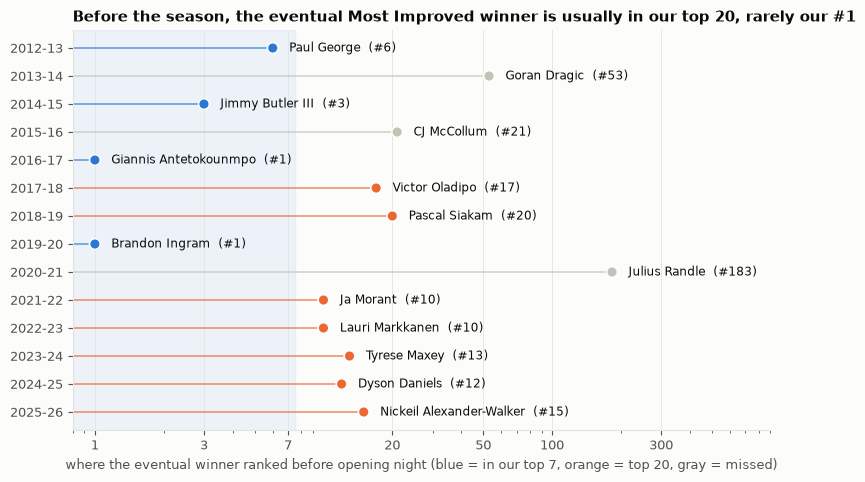

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.2))
h = history.iloc[::-1]
y = np.arange(len(h)); rk = h["his preseason rank"].to_numpy()
col = np.where(rk <= 7, BLUE, np.where(rk <= 20, ORANGE, MUTED))
ax.axvspan(0.8, 7.5, color=BLUE, alpha=0.07); ax.hlines(y, 0.8, rk, color=col, linewidth=1.4, alpha=0.6)
ax.scatter(rk, y, s=60, color=col, edgecolor=SURFACE, linewidth=1.2, zorder=3)
for yi, r, n in zip(y, rk, h["eventual winner"]):
    ax.text(r * 1.18, yi, f"{n}  (#{r})", va="center", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_xlim(0.8, 900); ax.set_xticks([1, 3, 7, 20, 50, 100, 300], ["1", "3", "7", "20", "50", "100", "300"])
ax.set_yticks(y, h.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("where the eventual winner ranked before opening night (blue = in our top 7, orange = top 20, gray = missed)")
ax.set_title("Before the season, the eventual Most Improved winner is usually in our top 20, rarely our #1", loc="left")
fig.savefig(FIG_DIR / "10_1_preseason_winner_ranks.png", dpi=150, bbox_inches="tight")

### 10.1B findings

**Preseason form is what makes a preseason prediction possible at all.**

| Inputs | Winner in our top 7 | In our top 20 | Median winner rank | vs a blind guess |
|---|---|---|---|---|
| Last season + profile | 4 of 14 | 5 | 38.5 | 2.2× |
| + momentum | 3 | 5 | 38 | 3.0× |
| **+ preseason form per 36 (used)** | **4** | **11** | **12.5** | **5.5×** |
| + preseason minute increases | 3 | 10 | 13.5 | 5.2× |
| + room-to-grow curve | 3 | 11 | 12.5 | 5.4× |

- **Preseason minute increases (option b) add nothing** once per-36 form is known, so they are **left out**. The carry-over in 10.1A is real, but it does not help separate the winner from the other 350 candidates.
- **The learned "room to grow" curve adds nothing either,** which is why the 22-point cut-off is a rule and not a model input.

**How good is this, honestly?**
- From about 350 candidates, the eventual winner was **our #1 twice** (Giannis Antetokounmpo 2016-17, Brandon Ingram 2019-20), **in our top 7 in 4 of 14 seasons** and **in our top 20 in 11 of 14**.
- Stricter test (train on earlier seasons only, 9 seasons): never #1, top 7 once, top 20 in 7, median rank 15.
- So **read the top 7 as a shortlist, not a forecast.** In most seasons the winner sits just outside it (ranks 10–21). Notebook 10's end-of-season model put the winner #1 in 8 of 15, because by then the leap had happened.
- **The big misses are the same two as in notebook 10:** Goran Dragić (53rd) and Julius Randle (183rd), both 26–27 years old with no preseason sign.

**The penalty (λ) is a judgment call.** A weaker penalty (λ = 0.1) put 7 of 14 winners in the top 7, but with only 14 winners, picking the best-scoring setting is tuning on the answers. I used **λ = 3**, the same as notebook 10. The stability table in 10.1C shows which picks survive either way.

## 10.1C — The 2026-27 prediction

The model is refitted on all 14 past preseasons and applied to this one.

In [9]:
model = ChoiceModel(LEAN, L2).fit(H)
everyone = frame[frame["season"] == TARGET].reset_index(drop=True)
everyone["chance"] = model.predict_proba(everyone)
removed = everyone[~everyone["candidate"] & (everyone["chance"].rank(ascending=False) <= 7)]
print("ruled out, but would have been in the top 7:", ", ".join(f"{r.player_name} (#{int((everyone['chance'] > r.chance).sum()) + 1}, "
      f"{'previous winner' if r.previous_winner else f'{r.ppg_last:.1f} points a game last season'})" for r in removed.itertuples()) or "nobody")
T = everyone[everyone["candidate"]].reset_index(drop=True)
T["chance"] = model.predict_proba(T)
T["rank"] = T["chance"].rank(ascending=False, method="min").astype(int)
T = T.sort_values("rank").reset_index(drop=True)

NICE = {"mpg_last": "minutes last season", "ppg_last": "points last season", "usg_last": "usage last season", "team_win_pct_last": "team's wins last season",
        "age": "age", "second_year": "second-year discount", "new_team": "new team", "momentum_game_score": "improved last season",
        "late_surge_last": "strong finish last season", "pre_game_score_change": "preseason production per 36",
        "pre_volume_change": "preseason shot volume per 36", "pre_ts_change": "preseason shooting efficiency", "pre_minutes_up": "preseason minutes up"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=LEAN)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)   # each input's push, vs the average candidate
T["why"] = [" + ".join(contrib.loc[i].nlargest(2).index) for i in T.index]

print(f"{len(T)} candidates; the top 7 hold {T['chance'].head(7).sum():.0%} of the total chance (a blind guess would give them {7 / len(T):.0%})")
show = T.head(7)[["rank", "player_name", "chance", "age", "ppg_last", "mpg_last", "pre_mpg", "pts36_last", "pts36", "ts_last", "ts", "pre_minutes"]].copy()
show.columns = ["rank", "player", "chance", "age", "points last season", "minutes last season", "preseason minutes per game",
                "points per 36 last season", "points per 36 preseason", "true shooting last season", "true shooting preseason", "preseason minutes"]
print(show.round(3).to_string(index=False))
show.set_index("rank").style.format({"chance": "{:.1%}", "age": "{:.0f}", "true shooting last season": "{:.1%}", "true shooting preseason": "{:.1%}"}, precision=1)

ruled out, but would have been in the top 7: Paolo Banchero (#5, 22.2 points a game last season), Luka Dončić (#1, 33.5 points a game last season), Jaylen Brown (#4, 28.7 points a game last season)


348 candidates; the top 7 hold 22% of the total chance (a blind guess would give them 2%)
 rank           player  chance    age  points last season  minutes last season  preseason minutes per game  points per 36 last season  points per 36 preseason  true shooting last season  true shooting preseason  preseason minutes
    1    Reed Sheppard   0.039 22.607              13.537               26.220                      22.000                     18.586                   27.000                      0.564                    0.694               44.0
    2   Stephon Castle   0.039 22.251              16.662               29.941                      19.500                     20.033                   24.923                      0.575                    0.654               39.0
    3        Ty Jerome   0.032 29.570              12.543               19.857                      16.000                     22.740                   33.750                      0.643                    0.680          

,player,chance,age,points last season,minutes last season,preseason minutes per game,points per 36 last season,points per 36 preseason,true shooting last season,true shooting preseason,preseason minutes
rank,,,,,,,,,,,
1,Reed Sheppard,3.9%,23,13.5,26.2,22.0,18.6,27.0,56.4%,69.4%,44.0
2,Stephon Castle,3.9%,22,16.7,29.9,19.5,20.0,24.9,57.5%,65.4%,39.0
3,Ty Jerome,3.2%,30,12.5,19.9,16.0,22.7,33.8,64.3%,68.0%,48.0
4,Rui Hachimura,3.0%,29,11.5,28.3,17.0,14.6,37.1,62.0%,76.2%,34.0
5,Amen Thompson,2.9%,24,18.3,37.4,27.0,17.6,14.7,59.4%,48.6%,54.0
6,Leonard Miller,2.7%,23,7.8,15.7,19.7,18.0,31.7,63.3%,75.1%,59.0
7,Tristan da Silva,2.4%,26,9.9,24.7,24.5,14.4,26.4,57.6%,55.1%,49.0


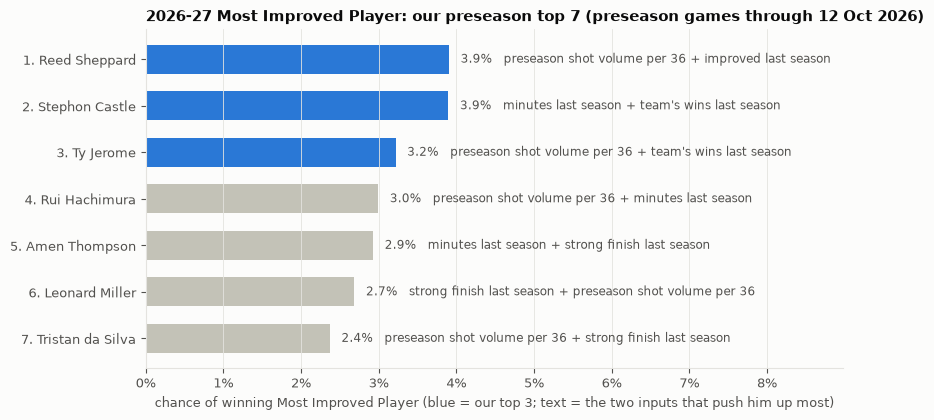

In [10]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + 0.0015, yi, f"{r['chance']:.1%}   {r['why']}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.3); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = our top 3; text = the two inputs that push him up most)")
last_date = now["game_date"].max()
ax.set_title(f"{TARGET} Most Improved Player: our preseason top 7 (preseason games through {last_date:%d %b %Y})", loc="left")
fig.savefig(FIG_DIR / "10_1_mip_preseason_top7.png", dpi=150, bbox_inches="tight")

In [11]:
weights = pd.Series(model.coef_, index=[NICE[c] for c in LEAN]).sort_values()
print("model weights (per standard deviation of each input):"); print(weights.round(2).to_string())
reasons = contrib.head(7).copy(); reasons.index = T["player_name"].head(7)
print(reasons.T.reindex(weights.index[::-1]).round(2).to_string())
reasons.T.reindex(weights.index[::-1]).style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1.5, vmax=1.5, axis=None)

model weights (per standard deviation of each input):
age                             -0.62
second-year discount            -0.51
improved last season             0.18
preseason production per 36      0.21
points last season               0.25
usage last season                0.27
preseason shooting efficiency    0.32
new team                         0.42
team's wins last season          0.44
strong finish last season        0.61
minutes last season              0.73
preseason shot volume per 36     0.83
player_name                    Reed Sheppard  Stephon Castle  Ty Jerome  Rui Hachimura  Amen Thompson  Leonard Miller  Tristan da Silva
preseason shot volume per 36            0.64           -0.05       0.88           1.95           0.29            1.03              1.56
minutes last season                     0.43            0.78      -0.15           0.63           1.46           -0.54              0.29
strong finish last season               0.52            0.39       0.42          -

player_name,Reed Sheppard,Stephon Castle,Ty Jerome,Rui Hachimura,Amen Thompson,Leonard Miller,Tristan da Silva
preseason shot volume per 36,+0.64,-0.05,+0.88,+1.95,+0.29,+1.03,+1.56
minutes last season,+0.43,+0.78,-0.15,+0.63,+1.46,-0.54,+0.29
strong finish last season,+0.52,+0.39,+0.42,-0.39,+0.63,+2.10,+0.89
team's wins last season,+0.38,+0.73,+0.80,+0.42,+0.38,-0.36,+0.13
new team,-0.29,-0.29,+0.57,+0.57,-0.29,-0.29,-0.29
preseason shooting efficiency,+0.25,+0.14,+0.08,+0.22,-0.24,+0.29,-0.05
usage last season,+0.20,+0.39,+0.31,-0.14,+0.12,+0.01,-0.08
points last season,+0.21,+0.37,+0.16,+0.10,+0.46,-0.09,+0.02
preseason production per 36,+0.04,+0.15,+0.22,+0.36,-0.19,+0.54,+0.21
improved last season,+0.59,+0.30,+0.37,-0.21,+0.23,-0.02,+0.18


In [12]:
# how stable is the top 7? refit under every setting from the sensitivity table and count appearances
settings = [(n, f, l2) for n, f in [("lean", LEAN), ("all", LAST_SEASON + PROFILE + MOMENTUM + PRE_FORM)] for l2 in [0.1, 1.0, 3.0, 10.0]]
alt = {}
for n, f, l2 in settings:
    p = ChoiceModel(f, l2).fit(H).predict_proba(T)
    alt[f"{n}, λ = {l2:g}"] = p.rank(ascending=False, method="min").astype(int)
alt = pd.DataFrame(alt); alt.index = T["player_name"]
stable = alt.assign(**{"settings in top 7 (of 8)": (alt <= 7).sum(axis=1), "median rank": alt.median(axis=1)})
stable = stable[stable["settings in top 7 (of 8)"] > 0].sort_values(["settings in top 7 (of 8)", "median rank"], ascending=[False, True])
stable[["settings in top 7 (of 8)", "median rank"] + list(alt.columns)]

,settings in top 7 (of 8),median rank,"lean, λ = 0.1","lean, λ = 1","lean, λ = 3","lean, λ = 10","all, λ = 0.1","all, λ = 1","all, λ = 3","all, λ = 10"
player_name,,,,,,,,,,
Stephon Castle,8,1.0,1,1,2,2,1,1,1,1
Reed Sheppard,8,2.0,2,2,1,1,3,2,2,2
Amen Thompson,6,3.0,3,3,5,10,2,3,3,8
Ty Jerome,5,5.0,5,5,3,5,28,9,5,9
Tristan da Silva,5,7.0,12,9,7,7,23,7,4,7
Rui Hachimura,4,6.5,4,4,4,9,14,5,8,10
Pelle Larsson,3,8.5,20,12,9,6,11,8,7,4
Tyrese Haliburton,3,9.5,11,6,10,12,9,4,6,11
Bennedict Mathurin,3,10.0,6,8,12,17,6,6,16,23


In [13]:
watch = ["Egor Dëmin", "Cooper Flagg", "Ryan Rollins", "Keyonte George", "Nickeil Alexander-Walker", "Luka Dončić"]
from unicorn.bref import normalize_name
key = frame[frame["season"] == TARGET].assign(k=lambda d: d["player_name"].map(normalize_name)).set_index("k")
rows = []
for name in watch:
    k = normalize_name(name)
    if k not in key.index:
        rows.append({"player": name, "note": "no preseason minutes yet / no baseline season"}); continue
    r = key.loc[k]; t = T[T["player_id"] == r["player_id"]]
    rows.append({"player": r["player_name"], "rank": int(t["rank"].iloc[0]) if len(t) else None, "chance": f"{t['chance'].iloc[0]:.2%}" if len(t) else "",
                 "note": "previous winner, excluded" if r["previous_winner"] else "established scorer, excluded" if r["established"] else ("second-year player" if r["second_year"] else ""),
                 "preseason minutes": round(r["pre_minutes"]), "points per 36: last season → preseason": f"{r['pts36_last']:.1f} → {r['pts36']:.1f}"})
pd.DataFrame(rows).set_index("player")

,rank,chance,note,preseason minutes,points per 36: last season → preseason
player,,,,,
Egor Dëmin,296.0,0.02%,second-year player,40,14.8 → 17.1
Cooper Flagg,44.0,0.55%,second-year player,44,22.6 → 27.0
Ryan Rollins,14.0,1.61%,,58,19.4 → 24.2
Keyonte George,NaN,,"established scorer, excluded",34,25.7 → 22.2
Nickeil Alexander-Walker,NaN,,"previous winner, excluded",39,22.5 → 22.2
Luka Dončić,NaN,,"established scorer, excluded",41,33.6 → 38.6


In [14]:
# why two second-year players rank where they do: each input's push, against the average candidate
second = contrib.copy(); second.index = T["player_name"]
pair = second.loc[["Egor Dëmin", "Cooper Flagg"]].T.reindex(weights.index[::-1])
pair.loc["total"] = pair.sum()
print(pair.round(2).to_string())
T.set_index("player_name").loc[["Egor Dëmin", "Cooper Flagg"], ["age", "ppg_last", "mpg_last", "usg_last", "team_win_pct_last", "late_surge_last", "momentum_game_score", "pre_minutes"]].round(2)

player_name                    Egor Dëmin  Cooper Flagg
preseason shot volume per 36         0.53          0.38
minutes last season                  0.33          1.11
strong finish last season           -0.72          0.29
team's wins last season             -0.75         -0.53
new team                            -0.29         -0.29
preseason shooting efficiency       -0.16          0.03
usage last season                    0.05          0.51
points last season                   0.04          0.60
preseason production per 36         -0.05          0.16
improved last season                -0.02         -0.02
second-year discount                -1.34         -1.34
age                                  0.80          0.90
total                               -1.59          1.79


,age,ppg_last,mpg_last,usg_last,team_win_pct_last,late_surge_last,momentum_game_score,pre_minutes
player_name,,,,,,,,
Egor Dëmin,20.92,10.31,25.10,0.18,0.24,-2.26,0.0,40.0
Cooper Flagg,20.12,21.04,33.56,0.26,0.32,1.68,0.0,44.0


### 10.1C findings

**Our 2026-27 Most Improved top 7** (preseason games through 12 October 2026):

| | Player | Chance | Why the model likes him |
|---|---|---|---|
| 1 | **Reed Sheppard** | 3.9% | Improved last season, finished it strongly, 22 years old, taking more shots per minute in preseason |
| 2 | **Stephon Castle** | 3.9% | Already plays 30 minutes for a winning team, 22 years old, 16.7 points a game with room above |
| 3 | **Ty Jerome** | 3.2% | Big preseason shot volume, new team; held back by age (29) |
| 4 | Rui Hachimura | 3.0% | The largest preseason shot-volume jump of the seven, new team; age 29 |
| 5 | Amen Thompson | 2.9% | 37 minutes a game last season and a strong finish; preseason has been poor |
| 6 | Leonard Miller | 2.7% | The strongest finish to last season of the seven, plus preseason volume; only 16 minutes a game last season |
| 7 | Tristan da Silva | 2.4% | Preseason shot volume and a strong finish |

**How to read it**
- **The chances are small on purpose.** The top 7 together hold 22%. The model is saying "the winner is probably someone else", which matches its history (top 7 in 4 of 14).
- **Sheppard and Castle are the stable picks:** top 7 under all 8 model settings, and #1 or #2 in most. Amen Thompson is in 6 of 8. The names from 3 to 7 change with the settings (Pelle Larsson, Tyrese Haliburton, Bennedict Mathurin and GG Jackson move in and out).
- **Preseason evidence is thin so far.** Each of the seven has played 34–59 preseason minutes, so their preseason form currently counts for about a fifth of its face value. Rui Hachimura's 37 points per 36 comes from 34 minutes.
- **Three players were ruled out by the 22-point rule** and would otherwise be in the top 7: Luka Dončić (#1), Jaylen Brown (#4) and Paolo Banchero (#5). Banchero averaged 22.2, right on the line, so he depends entirely on where that line is drawn.

**Second-year players**
- **Cooper Flagg is 44th (0.55%)** and **Egor Dëmin 296th (0.02%).** Both lose the same amount for being second-year players (the discount found in notebook 10: often on ballots, never winners).
- Flagg's 34 minutes and 21 points a game outweigh it. Dëmin's case is also held back by a weak finish to last season (2.3 game score lower after the All-Star break) and a team that won 24% of its games. His preseason so far is mildly positive: 14.8 → 17.1 points per 36, in 40 minutes.
- This is the MIP question only. Notebook 07's breakout outlook for Dëmin is a different question, with no second-year discount.

**Open decisions (yours)**
1. **The 22-point rule.** Keep it, move it (20 would also remove Flagg at 21.0; 25 would let Banchero back into the top 7), or drop it.
2. **Excluding previous winners.** Removes Nickeil Alexander-Walker and others.
3. **The penalty.** λ = 3 (cautious, used) or λ = 0.1 (better on history, but likely over-fitted): that version's top 3 is Castle, Sheppard, Thompson.

**Next:** re-run when preseason ends, then track these seven against notebook 10's live MIP race during the season.